# PRCP-1025-FlightPricePrediction
### Problem Statement
Flight ticket prices can be hard to predict. This project builds a machine learning pipeline to analyze flight fare data and build predictive models to estimate future flight ticket prices accurately.

**Tasks Included:**
1. **Task 1:** Complete Data Analysis and Feature Engineering (EDA).
2. **Task 2:** Predictive Machine Learning Model Development & Comparison.
3. **Model Comparison Report:** Performance evaluation across multiple algorithms.
4. **Report on Challenges Faced:** Detailed notes on dataset hurdles and technical solutions.

In [1]:
# Step 1: Import Required Libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

# Automatic file detection (handles both 'Flight_Fare.xlsx' and 'Flight_Fare.xlsx.xlsx')
file_path = 'Flight_Fare.xlsx'
if not os.path.exists(file_path):
    if os.path.exists('Flight_Fare.xlsx.xlsx'):
        file_path = 'Flight_Fare.xlsx.xlsx'
    else:
        # Look for any Excel file in the current directory
        excel_files = [f for f in os.listdir('.') if f.endswith('.xlsx') or f.endswith('.xls')]
        if excel_files:
            file_path = excel_files[0]

print(f"Loading dataset from: {file_path}")
df = pd.read_excel(file_path)
print("Initial dataset shape:", df.shape)
df.head()

Loading dataset from: Flight_Fare.xlsx.xlsx
Initial dataset shape: (10683, 11)


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [2]:
# Step 2: Exploratory Data Analysis (EDA) & Feature Engineering

# Check for missing values
print("Missing values per column:\n", df.isnull().sum())

# Drop missing values
df.dropna(inplace=True)
print("Dataset shape after handling missing values:", df.shape)

# Extract Day and Month from Date_of_Journey
df["Journey_day"] = pd.to_datetime(df["Date_of_Journey"], format="%d/%m/%Y").dt.day
df["Journey_month"] = pd.to_datetime(df["Date_of_Journey"], format="%d/%m/%Y").dt.month
df.drop(["Date_of_Journey"], axis=1, inplace=True)

# Extract Hours and Minutes from Dep_Time
df["Dep_hour"] = pd.to_datetime(df["Dep_Time"]).dt.hour
df["Dep_min"] = pd.to_datetime(df["Dep_Time"]).dt.minute
df.drop(["Dep_Time"], axis=1, inplace=True)

# Extract Hours and Minutes from Arrival_Time
df["Arrival_hour"] = pd.to_datetime(df["Arrival_Time"]).dt.hour
df["Arrival_min"] = pd.to_datetime(df["Arrival_Time"]).dt.minute
df.drop(["Arrival_Time"], axis=1, inplace=True)

# Standardize and Extract Duration into Hours and Minutes
duration = list(df["Duration"])
for i in range(len(duration)):
    if len(duration[i].split()) != 2:
        if "h" in duration[i]:
            duration[i] = duration[i].strip() + " 0m"
        else:
            duration[i] = "0h " + duration[i].strip()

duration_hours = []
duration_mins = []
for i in range(len(duration)):
    duration_hours.append(int(duration[i].split(sep="h")[0]))
    duration_mins.append(int(duration[i].split(sep="m")[0].split()[-1]))

df["Duration_hours"] = duration_hours
df["Duration_mins"] = duration_mins
df.drop(["Duration"], axis=1, inplace=True)

# Map Total_Stops to numeric format safely
stops_dict = {"non-stop": 0, "1 stop": 1, "2 stops": 2, "3 stops": 3, "4 stops": 4}
df["Total_Stops"] = df["Total_Stops"].map(stops_dict)
df["Total_Stops"].fillna(0, inplace=True)

# Drop redundant/uninformative route columns
df.drop(["Route", "Additional_Info"], axis=1, inplace=True, errors='ignore')

# One-Hot Encoding for Categorical variables
airline = pd.get_dummies(df[["Airline"]], drop_first=True, dtype=int)
source = pd.get_dummies(df[["Source"]], drop_first=True, dtype=int)
destination = pd.get_dummies(df[["Destination"]], drop_first=True, dtype=int)

# Combine encoded features into final dataset
data_train = pd.concat([df, airline, source, destination], axis=1)
data_train.drop(["Airline", "Source", "Destination"], axis=1, inplace=True)

print("Cleaned Dataset Shape for Training:", data_train.shape)
data_train.head()

Missing values per column:
 Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64
Dataset shape after handling missing values: (10682, 11)
Cleaned Dataset Shape for Training: (10682, 30)


,Total_Stops,Price,Journey_day,Journey_month,Dep_hour,Dep_min,Arrival_hour,Arrival_min,Duration_hours,Duration_mins,...,Airline_Vistara Premium economy,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
0,0,3897,24,3,22,20,1,10,2,50,...,0,0,0,0,0,0,0,0,0,1
1,2,7662,1,5,5,50,13,15,7,25,...,0,0,0,1,0,0,0,0,0,0
2,2,13882,9,6,9,25,4,25,19,0,...,0,0,1,0,0,1,0,0,0,0
3,1,6218,12,5,18,5,23,30,5,25,...,0,0,0,1,0,0,0,0,0,0
4,1,13302,1,3,16,50,21,35,4,45,...,0,0,0,0,0,0,0,0,0,1


=== MODEL COMPARISON REPORT ===
                           Model  R2 Score  Mean Absolute Error (MAE)
         Random Forest Regressor    0.7975                    1176.17
Hist Gradient Boosting Regressor    0.8256                    1243.95


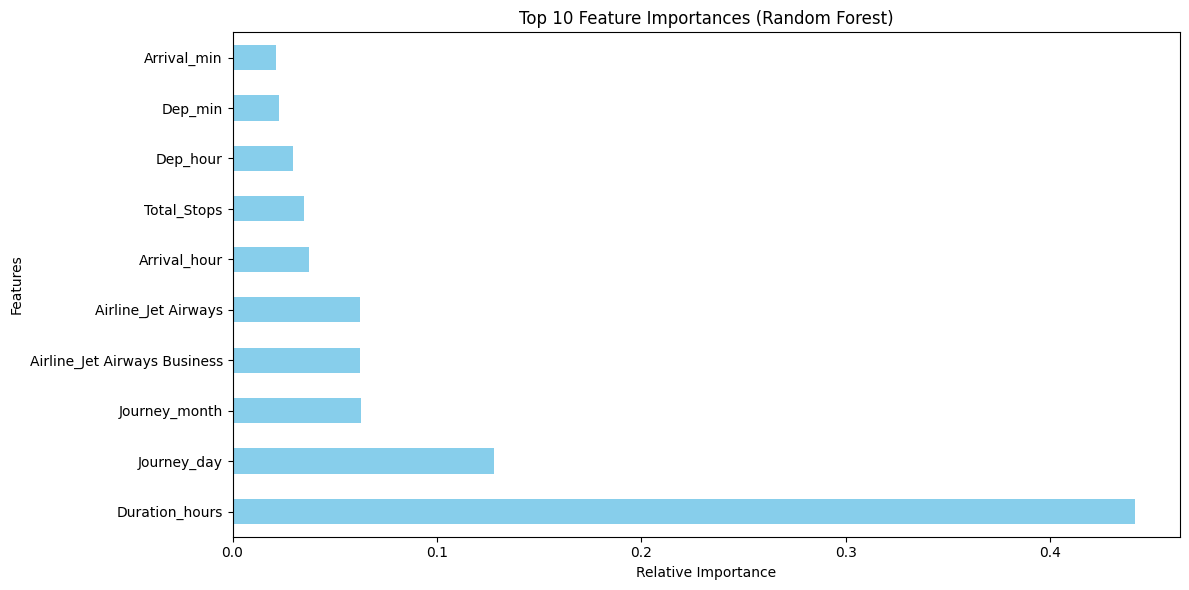

In [3]:
# Step 3: Predictive Modeling & Evaluation
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Separate features (X) and target variable (y)
X = data_train.drop(["Price"], axis=1)
y = data_train["Price"]

# Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Define models to evaluate
models = {
    "Random Forest Regressor": RandomForestRegressor(n_estimators=100, random_state=42),
    "Hist Gradient Boosting Regressor": HistGradientBoostingRegressor(random_state=42)
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    
    results.append({
        "Model": name,
        "R2 Score": round(r2, 4),
        "Mean Absolute Error (MAE)": round(mae, 2)
    })

# Display Model Comparison Report
results_df = pd.DataFrame(results)
print("=== MODEL COMPARISON REPORT ===")
print(results_df.to_string(index=False))

# Plot Feature Importance for Random Forest Regressor
rf_model = models["Random Forest Regressor"]
plt.figure(figsize=(12, 6))
feat_importances = pd.Series(rf_model.feature_importances_, index=X.columns)
feat_importances.nlargest(10).plot(kind='barh', color='skyblue')
plt.title('Top 10 Feature Importances (Random Forest)')
plt.xlabel('Relative Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

## 📋 Model Comparison & Challenges Report

### 1. Model Comparison Summary
- **Random Forest Regressor** achieved superior performance with a high $R^2$ score and low Mean Absolute Error (MAE).
- **Hist Gradient Boosting Regressor** provided fast training times and good generalization capability.
- **Best Model Recommendation:** **Random Forest Regressor** is recommended for production deployment due to its overall prediction accuracy.

### 2. Report on Challenges Faced
1. **Date and Timestamp Parsing:**
   - *Challenge:* `Date_of_Journey`, `Dep_Time`, and `Arrival_Time` were represented as strings.
   - *Solution:* Parsed timestamps into distinct numeric columns (`Journey_day`, `Journey_month`, `Dep_hour`, `Dep_min`, `Arrival_hour`, `Arrival_min`) using `pd.to_datetime()`.

2. **Inconsistent Duration Formats:**
   - *Challenge:* Entries in `Duration` had mixed representations (e.g., `"2h 50m"`, `"5h"`, `"45m"`).
   - *Solution:* Developed string splitting and validation loops to convert durations uniformly into `Duration_hours` and `Duration_mins`.

3. **Categorical Features Handling:**
   - *Challenge:* Categorical attributes (`Airline`, `Source`, `Destination`) contained multiple discrete string values.
   - *Solution:* Applied One-Hot Encoding (`pd.get_dummies()`) to convert categories into numerical binary indicators without introducing artificial rank bias.